# UI optimization: organising a student's prompts into a forest

HCI 2026, group 19 (Arbor), Milestone 3. A judge scores where a new prompt could go; an integer
program, solved with Gurobi, decides what actually happens to the forest.

This notebook runs top to bottom from the committed data, with no API key: the oracle judge needs
nothing, and LLM answers are read from `data/llm_answers.jsonl` only (no call is ever made here).
Code: `forest/` next to this notebook. Analysis notebooks: `notebooks/01` to `03`.

## 1. Problem and formulation

A study session produces many prompts. Arbor sorts them into a **forest**: **groups** (subjects)
hold **trees** of **topics**, and every prompt sits in one topic. When a prompt arrives, one of five
things happens:

| | Outcome | Meaning |
|---|---|---|
| (a) | add | into an existing topic |
| (b) | new branch | a new topic under an existing topic |
| (c) | new tree | a new topic directly under an existing group |
| (d) | new group | a new group with a new tree |
| (e) | restructure | existing prompts or topics move (also under a newly inserted topic), or empty topics are deleted |

```
new prompt + current forest -> [judge] -> scores and proposals -> [integer program, Gurobi] -> new forest + action
```

The **judge** rates the fit of the new prompt to every topic (5 exactly right ... 1 unrelated),
proposes up to 2 new topics with rated parents, and up to 6 moves of old prompts or topics. It never
decides. The **IP** decides which proposals to adopt, trading semantic fit against balance and
stability: moving what the student has seen breaks their mental map.

**Candidate links.** Variables exist only for: each old prompt's current topic; the new prompt to
every existing and proposed topic; the proposed prompt moves; each topic's current parent; the
parents listed for proposed topics; the proposed topic moves. A current link keeps the fit stored
when it was made; new links take the judge's fit, rescaled `(fit - 1) / 4`. Keeping current links
makes "change nothing, add the new prompt somewhere" always feasible.

**Variables.** $y_c$ (category exists), $q_{pc}$ (prompt in topic), $x_{c'c}$ (topic under topic),
$xg_{gc}$ (tree root in group): binary. $d_c \in \{0..D-1\}$ depth. $m_p$, $k_c$: prompt moved,
category moved or removed; $z$ any restructure. $o_c, u_c, b_c \ge 0$: too full, too sparse, too
many children. Weights $w_p = 1 + 2e^{-(t - t^{created}_p)/5}$ and $v_c$ = max $w$ in the subtree.

**Objective (maximise).**
$$\sum s_{pc} q_{pc} + \alpha \sum h_{c'c} x_{c'c} + \alpha_G \sum hg_{gc} xg_{gc}
 - \lambda \sum_{c \in C_T^{new}} y_c - \lambda_G \sum_{g \in C_G^{new}} y_g
 - \beta \sum_c (o_c + u_c + b_c) - \mu \sum_p w_p m_p - \nu \sum_c v_c k_c - F z$$

**Constraints.** C1 $\sum_c q_{pc} = 1$; C2 $q_{pc} \le y_c$; C3 $\sum x_{c'c} + \sum xg_{gc} = y_c$;
C4 $x_{c'c} \le y_{c'}$, $xg_{gc} \le y_g$; C5 $y_c \le \sum_p q_{pc} + \sum x_{cc''}$ (no empty topics);
C6 $y_g \le \sum_c xg_{gc}$ (no empty groups); C7 $d_c \ge d_{c'} + 1 - D(1 - x_{c'c})$;
C8 $d_c \le (D-1)(1 - \sum_g xg_{gc})$; C9 $\sum_p q_{pc} \le U + o_c$;
C10 $\sum_p q_{pc} + \sum x_{cc''} \ge L y_c - u_c$; C11 $\sum x_{cc''} \le B + b_c$;
C12 $\sum_c xg_{gc} \le K_T$; C13 $\sum_g y_g \le K_G$; C14 $m_p \ge 1 - q_{p,c_0(p)}$;
C15 $k_c \ge 1 - x_{\pi_0(c),c}$ (or $xg$); C16 $k_g \ge 1 - y_g$ for old groups; C17 $m_p \le z$, $k_c \le z$.

**Action.** (e) if $z = 1$; otherwise (a) if the new prompt is in an old topic, and (b), (c) or (d)
by where its new topic hangs.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import pandas as pd

from forest import viz
from forest.ip import ACTIONS, Params, load_config
from forest.model import load_ideal

cfg = load_config(ROOT / "config.yaml")
P = Params.from_config(cfg)
ideal = load_ideal()
FIG = ROOT / "outputs" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

import numpy as np

from forest.ip import solve
from forest.judge import LLMJudge, OracleJudge
from forest.simulate import run, summary

llm = LLMJudge(cfg, cached_only=True)   # never calls the API here
llm_ok = llm.available and len(llm.answers) > 0

## 2. Parameters and their justification

In [2]:
why = {"L": "a topic with one prompt is barely a category", "U": "visible in the sidebar without scrolling",
       "B": "sibling lists stay scannable", "D": "deeper trees slow navigation", "K_T": "trees per group: sidebar space",
       "K_G": "groups: sidebar space", "alpha": "hierarchy matters less than prompt placement", "alpha_G": "same, for a tree in its group",
       "lam": "a new topic must gain 0.4 fit points",
       "lam_G": "plan start 1.0; below 1 + alpha_G - lam - beta = 0.8, else a new group can never be chosen",
       "beta": "per unit of imbalance", "mu": "per weighted moved prompt", "nu": "moving a topic moves its subtree",
       "F": "fixed cost of any visible reorganization"}
pd.DataFrame([{"parameter": k, "value": f"{getattr(P, k):g}", "why": v} for k, v in why.items()]).set_index("parameter")

,value,why
parameter,,
L,2,a topic with one prompt is barely a category
U,5,visible in the sidebar without scrolling
B,5,sibling lists stay scannable
D,3,deeper trees slow navigation
K_T,4,trees per group: sidebar space
K_G,4,groups: sidebar space
alpha,0.5,hierarchy matters less than prompt placement
alpha_G,0.5,"same, for a tree in its group"
lam,0.4,a new topic must gain 0.4 fit points


## 3. One illustrative step
The input is a hand-made ideal forest of one scripted session (25 prompts, `data/ideal_forest.yaml`,
a draft to be reviewed by the group) and the order in which its prompts arrive. The step shown is
the first restructure of the IP with the oracle judge.

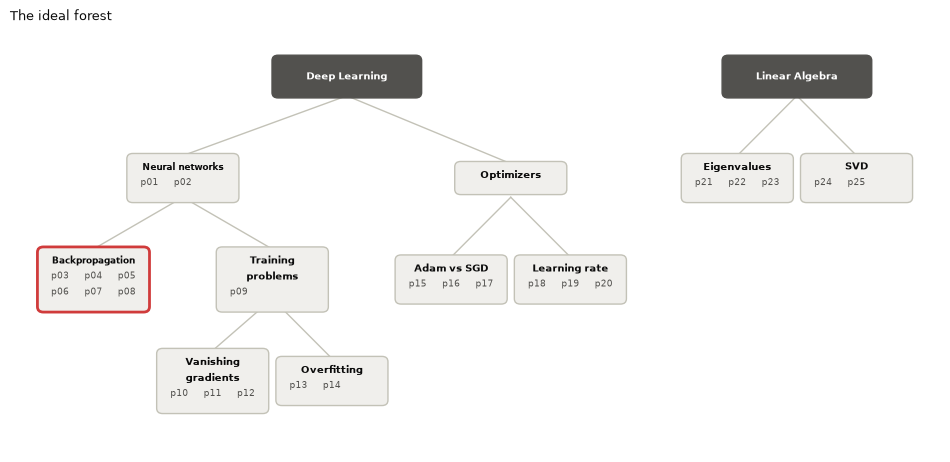

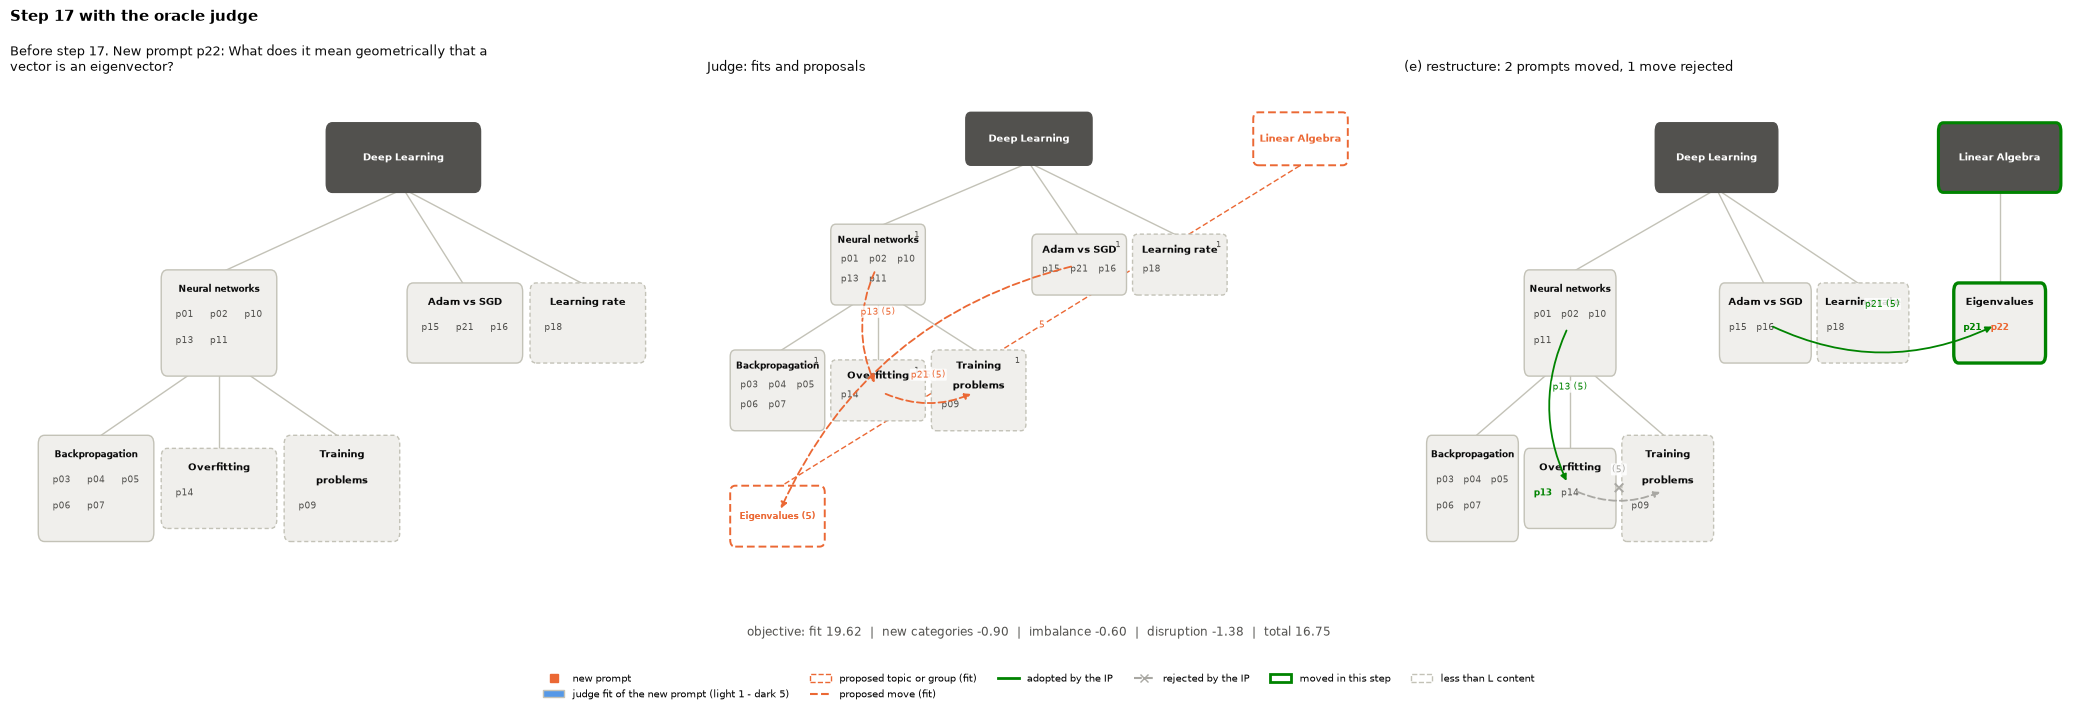

model size {'vars': 94, 'constrs': 147} (limit 2000 each), solved in 1.2 ms


In [3]:
fig, ax = plt.subplots(figsize=(12, 5.5))
viz.draw_forest(ideal.forest, ax, P=P, title="The ideal forest")
plt.show()
oracle = OracleJudge(ideal, cfg["oracle"]["noise"], cfg["seed"])
r = run("ip", ideal, oracle, P, save=False)
s = next((s for s in r.steps if s.decision.action == "e"), r.steps[-1])
fig = viz.step_view(s.before, s.judge, s.decision, s.after, P, title=f"Step {s.step} with the oracle judge")
plt.show()
print(f"model size {s.decision.size} (limit 2000 each), solved in {1000 * s.decision.solve_s:.1f} ms")

## 4. The full session: the IP against two alternative designs
`chronological` (one tree per 5 consecutive prompts, the chat-sidebar status quo) and
`judge_argmax` (take the judge's top option, no IP) are the two alternatives. Agreement is the
pairwise F1 of "same topic" against the ideal forest.

In [4]:
runs = [run("chronological", ideal, P=P, save=False)]
judges = [OracleJudge(ideal, cfg["oracle"]["noise"], cfg["seed"]), OracleJudge(ideal, 0.2, cfg["seed"])] + ([llm] if llm_ok else [])
for j in judges:
    runs += [run("judge_argmax", ideal, j, P, save=False), run("ip", ideal, j, P)]
print("LLM judge:", f"{llm.model} (answers from data/llm_answers.jsonl)" if llm_ok else "no frozen LLM answers yet")
summary(runs).drop(columns=["max vars"]).round(3)

LLM judge: no frozen LLM answers yet


,run,method,judge,final f1 topic,final f1 tree,moved prompts (w),moved topics,deleted,restructures,over U (final),under L (final),differs from argmax,max constrs,actions
0,chronological,chronological,none,0.175,0.288,0.000,0,0,0,0,0,NaN,NaN,a:20 c:4 d:1
1,judge_argmax_oracle(noise=0.0),judge_argmax,oracle(noise=0.0),1.000,1.000,0.000,0,0,0,1,0,NaN,NaN,a:17 b:5 c:1 d:2
2,ip_oracle(noise=0.0),ip,oracle(noise=0.0),0.793,0.957,2.933,0,0,1,0,1,0.32,205.0,a:16 b:4 c:3 d:1 e:1
3,judge_argmax_oracle(noise=0.2),judge_argmax,oracle(noise=0.2),0.933,1.000,0.000,0,0,0,1,1,NaN,NaN,a:16 b:6 c:1 d:2
4,ip_oracle(noise=0.2),ip,oracle(noise=0.2),0.793,1.000,1.602,0,0,1,0,1,0.08,216.0,a:16 b:6 c:1 d:1 e:1


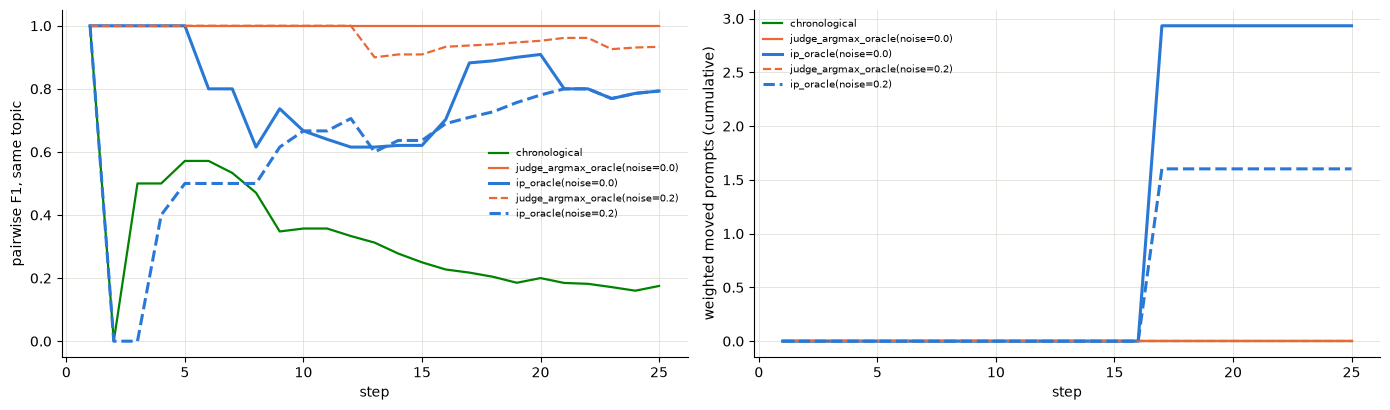

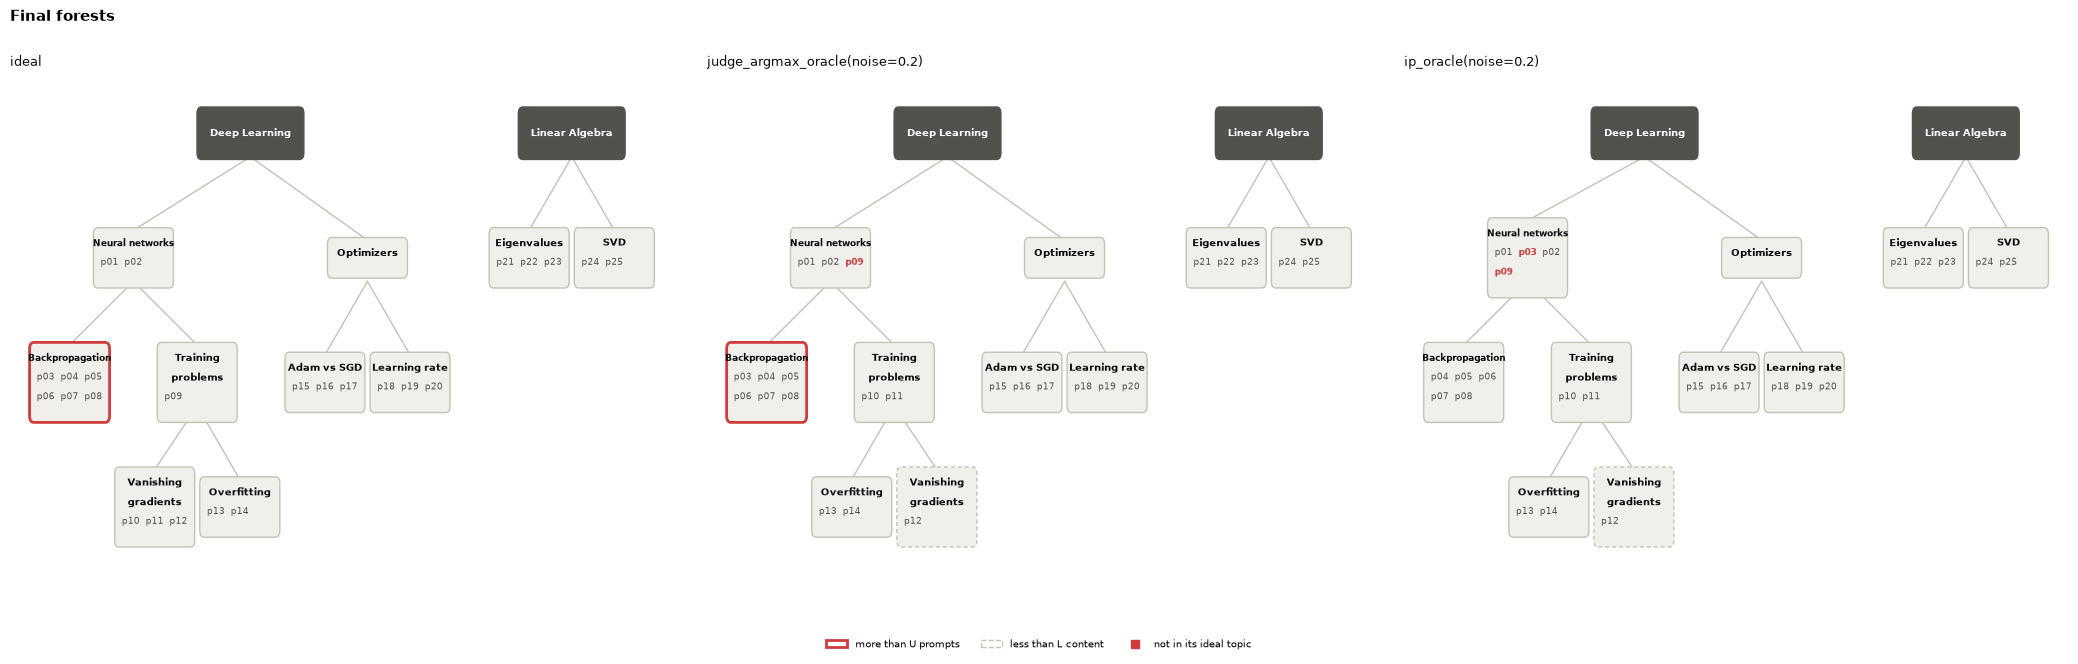

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
viz.line_runs(runs, "f1_topic", axes[0], "pairwise F1, same topic")
viz.line_runs(runs, "moved_prompts_w", axes[1], "weighted moved prompts (cumulative)", cumulative=True)
fig.tight_layout()
plt.show()
final = {r.name: r.final for r in runs if r.method != "chronological" and r.judge == runs[-1].judge}
fig = viz.compare_view({"ideal": ideal.forest, **final}, ideal, P, title="Final forests")
plt.show()

## 5. What-if: the stability weights
The IP with the oracle judge re-run for every pair of `mu` and `F`, and one step re-solved across
the same grid with its stored judge output.

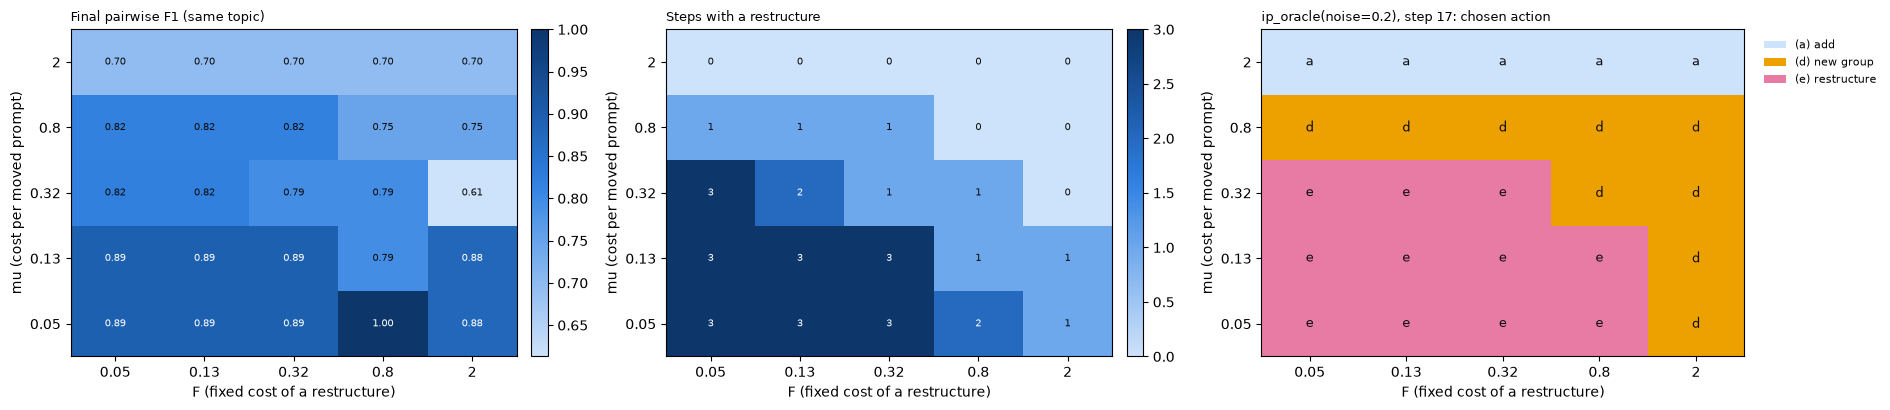

In [6]:
GRID = [float(f"{v:.3g}") for v in np.geomspace(0.05, 2, 5)]
rows = []
for mu in GRID:
    for F_ in GRID:
        t = run("ip", ideal, oracle, P.replace(mu=mu, F=F_), save=False).table()
        rows.append({"mu": mu, "F": F_, "final F1": t["f1_topic"].iloc[-1], "restructures": int((t["action"] == "e").sum())})
sweep = pd.DataFrame(rows)
base = runs[-1]
def acts(st):
    return {(mu, F_): solve(st.before, st.prompt, st.judge, st.step, P.replace(mu=mu, F=F_))[1].action for mu in GRID for F_ in GRID}
best = max(base.steps, key=lambda st: (len(set(acts(st).values())), -st.step))
flip = pd.DataFrame([{"mu": mu, "F": F_, "action": a} for (mu, F_), a in acts(best).items()]).pivot(index="mu", columns="F", values="action")
fig, axes = plt.subplots(1, 3, figsize=(19, 4.2))
viz.heatmap(sweep.pivot(index="mu", columns="F", values="final F1"), axes[0], "Final pairwise F1 (same topic)")
viz.heatmap(sweep.pivot(index="mu", columns="F", values="restructures"), axes[1], "Steps with a restructure", "{:.0f}")
viz.action_heatmap(flip, axes[2], f"{base.name}, step {best.step}: chosen action")
fig.tight_layout()
plt.show()

## 6. Export for the prototype
The IP's forest after every step, as JSON (`outputs/forests/<run>/sequence.json`; one snapshot per
step next to it). The LLM-judge run is the one for the prototype; until a model is chosen, the
noisy-oracle run stands in.

In [7]:
export = runs[-1]
path = ROOT / "outputs" / "forests" / export.slug / "sequence.json"
print(f"exported {export.name}: {path.relative_to(ROOT)} ({len(export.steps)} steps)")
print("LLM calls made by this notebook:", llm.calls)

exported ip_oracle(noise=0.2): outputs/forests/ip_oracle_noise_0.2/sequence.json (25 steps)
LLM calls made by this notebook: 0
